In [1]:
import pandas as pd

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Paper3/data/unsupervised_customers.csv")

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   annual_income_k  100 non-null    float64
 1   spending_score   100 non-null    float64
 2   age              100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

scaler = StandardScaler()
X = scaler.fit_transform(df)

model = KMeans(n_clusters=4, n_init=10, random_state=42)
model.fit(X)

labels = model.labels_
df["clusters"] = labels

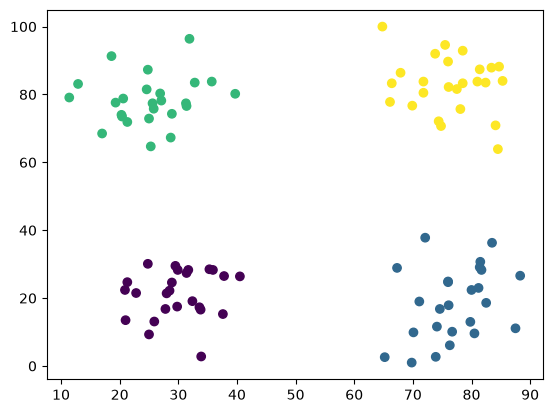

In [13]:
import matplotlib.pyplot as plt

plt.scatter(df["annual_income_k"], df["spending_score"], c=labels)

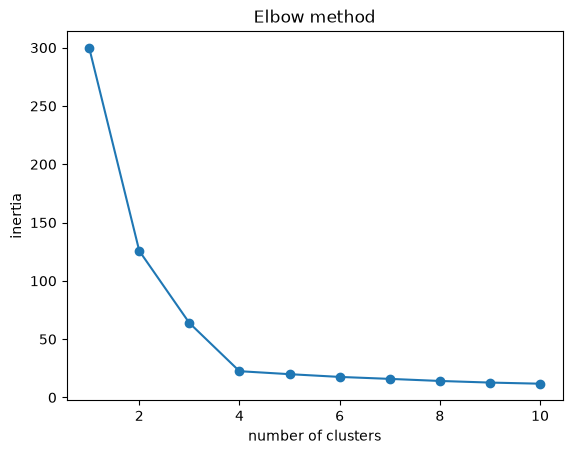

In [ ]:
import matplotlib.pyplot as plt

inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    inertia.append(model.inertia_)
    
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("number of clusters")
plt.ylabel("inertia")
plt.title("Elbow method")
plt.show()
plt.scatter